In [1]:
import pickle
from pathlib import Path

out_dir = Path("/Users/javier/FLAMES_30dor/gausspyp_v02.1/gausspy_validation")

FILENAME_DATA = out_dir / "real_FLAMES_validation_input.pkl"
FILENAME_DATA_DECOMP = out_dir / "real_FLAMES_validation_decomposed.pkl"
FILENAME_DF_VALIDATION = out_dir / "df_validation.pkl"
FILENAME_CONFIG = out_dir / "validation_training_config.pkl"

with open(FILENAME_DATA, "rb") as f:
    gauss_input = pickle.load(f)

with open(FILENAME_DATA_DECOMP, "rb") as f:
    data_decomp = pickle.load(f)

with open(FILENAME_DF_VALIDATION, "rb") as f:
    df_validation = pickle.load(f)

with open(FILENAME_CONFIG, "rb") as f:
    training_config = pickle.load(f)

print("gauss_input:", type(gauss_input))
print("data_decomp:", type(data_decomp))
print("df_validation:", type(df_validation))
print("training_config:", training_config)

gauss_input: <class 'dict'>
data_decomp: <class 'dict'>
df_validation: <class 'pandas.core.frame.DataFrame'>
training_config: {'phase': 'two', 'alpha1': 0.9, 'alpha2': 1.72, 'SNR_thresh': [10, 10], 'input_file': '/Users/javier/FLAMES_30Dor/gausspyp_v02.1/gausspy_validation/real_FLAMES_validation_input.pkl', 'decomposition_file': '/Users/javier/FLAMES_30Dor/gausspyp_v02.1/gausspy_validation/real_FLAMES_validation_decomposed.pkl', 'notes': 'FLAMES 30 Dor validation sample using trained GaussPy two-phase parameters.'}


In [2]:
import numpy as np
import pandas as pd


def make_validation_summary(
    gauss_input,
    data_decomp,
    lambda0_nm=656.279,
    rchi2_threshold=20,
    many_components_threshold=5,
):
    """
    Build a compact validation summary table for GaussPy decompositions.

    One row corresponds to one analyzed spectrum.

    Parameters
    ----------
    gauss_input : dict
        Input dictionary used for GaussPy decomposition. Must contain:
        'data_list', 'x_values', 'errors', and 'metadata'.

    data_decomp : dict
        Output dictionary returned by GaussPy batch_decomposition.

    lambda0_nm : float, default=656.279
        Rest wavelength used to convert fitted centers into velocity.
        For Halpha, lambda0_nm ≈ 656.279 nm.

    rchi2_threshold : float, default=20
        Threshold above which the fit is flagged as large chi-square.

    many_components_threshold : int, default=5
        Threshold above which the fit is flagged as having many components.

    Returns
    -------
    summary : pandas.DataFrame
        Validation summary table.
    """

    c_kms = 299792.458

    rows = []

    n_spectra = len(gauss_input["data_list"])

    for i in range(n_spectra):

        metadata = gauss_input["metadata"][i]

        wave = np.asarray(metadata["wave"], dtype=float)

        if len(wave) > 1:
            dw = np.nanmedian(np.diff(wave))
        else:
            dw = np.nan

        wave0 = wave[0] if len(wave) > 0 else np.nan
        wave_min = np.nanmin(wave) if len(wave) > 0 else np.nan
        wave_max = np.nanmax(wave) if len(wave) > 0 else np.nan

        means_fit_chan = np.asarray(data_decomp["means_fit"][i], dtype=float)
        fwhms_fit_chan = np.asarray(data_decomp["fwhms_fit"][i], dtype=float)
        amps_fit = np.asarray(data_decomp["amplitudes_fit"][i], dtype=float)

        means_initial = np.asarray(data_decomp["means_initial"][i], dtype=float)
        fwhms_initial = np.asarray(data_decomp["fwhms_initial"][i], dtype=float)
        amps_initial = np.asarray(data_decomp["amplitudes_initial"][i], dtype=float)

        means_fit_err_chan = np.asarray(data_decomp["means_fit_err"][i], dtype=float)
        fwhms_fit_err_chan = np.asarray(data_decomp["fwhms_fit_err"][i], dtype=float)
        amps_fit_err = np.asarray(data_decomp["amplitudes_fit_err"][i], dtype=float)

        ncomp_initial = len(means_initial)
        ncomp_fit = len(means_fit_chan)

        rchi2 = to_scalar(data_decomp["best_fit_rchi2"][i])

        # Convert channel quantities to wavelength quantities.
        means_fit_nm = wave0 + means_fit_chan * dw
        fwhms_fit_nm = fwhms_fit_chan * dw

        # Convert wavelength quantities to velocity quantities.
        means_fit_kms = c_kms * (means_fit_nm - lambda0_nm) / lambda0_nm
        fwhms_fit_kms = c_kms * fwhms_fit_nm / lambda0_nm

        # Compute sigma
        sigma_obs_kms = fwhms_fit_kms / 2.335
        sigma_kms = (sigma_obs_kms**2-7.8**2-9.1**2)**0.5

        # Basic automatic flags.
        flag_zero_components = ncomp_fit == 0
        flag_many_components = ncomp_fit > many_components_threshold
        flag_large_rchi2 = np.isfinite(rchi2) and rchi2 > rchi2_threshold

        if ncomp_fit > 0:
            flag_center_outside_window = np.any(
                (means_fit_nm < wave_min) | (means_fit_nm > wave_max)
            )
            flag_nonpositive_fwhm = np.any(fwhms_fit_chan <= 0)
        else:
            flag_center_outside_window = False
            flag_nonpositive_fwhm = False

        # Simple automatic quality label.
        if flag_zero_components:
            auto_quality = "zero_components"
        elif flag_nonpositive_fwhm:
            auto_quality = "nonpositive_fwhm"
        elif flag_center_outside_window:
            auto_quality = "center_outside_window"
        elif flag_large_rchi2:
            auto_quality = "large_rchi2"
        elif flag_many_components:
            auto_quality = "many_components"
        else:
            auto_quality = "ok_candidate"

        row = {
            # Identification
            "validation_index": metadata.get("validation_index", i),
            "filename": metadata.get("filename", None),
            "object": metadata.get("object", None),
            "ra_deg": metadata.get("ra_deg", None),
            "dec_deg": metadata.get("dec_deg", None),
            "sample": metadata.get("sample", None),

            # Wavelength window
            "wave_min_nm": wave_min,
            "wave_max_nm": wave_max,
            "dw_nm": dw,

            # Component counts
            "ncomp_initial": ncomp_initial,
            "ncomp_fit": ncomp_fit,

            # Fit quality
            "best_fit_rchi2": rchi2,

            # Raw GaussPy outputs in channel units
            "means_initial_chan": means_initial,
            "fwhms_initial_chan": fwhms_initial,
            "amps_initial": amps_initial,

            "means_fit_chan": means_fit_chan,
            "fwhms_fit_chan": fwhms_fit_chan,
            "amps_fit": amps_fit,

            "means_fit_err_chan": means_fit_err_chan,
            "fwhms_fit_err_chan": fwhms_fit_err_chan,
            "amps_fit_err": amps_fit_err,

            # Converted quantities
            "means_fit_nm": means_fit_nm,
            "fwhms_fit_nm": fwhms_fit_nm,
            "means_fit_kms": means_fit_kms,
            "fwhms_fit_kms": fwhms_fit_kms,

            # Dispersion
            "sigma_obs_kms": sigma_obs_kms,
            "sigma_kms": sigma_kms,


            # Automatic flags
            "flag_zero_components": flag_zero_components,
            "flag_many_components": flag_many_components,
            "flag_large_rchi2": flag_large_rchi2,
            "flag_center_outside_window": flag_center_outside_window,
            "flag_nonpositive_fwhm": flag_nonpositive_fwhm,
            "auto_quality": auto_quality,

            # Manual validation fields
            "visual_quality": "",
            "notes": "",
        }

        rows.append(row)

    summary = pd.DataFrame(rows)

    return summary


In [3]:
def to_scalar(value, default=np.nan):
    """
    Convert GaussPy scalar-like outputs to a float.

    Handles cases like:
    - 1.23
    - [1.23]
    - np.array([1.23])
    - None
    """
    if value is None:
        return default

    arr = np.asarray(value)

    if arr.size == 0:
        return default

    return float(arr.ravel()[0])

In [4]:
df_validation_summary = make_validation_summary(
    gauss_input,
    data_decomp,
    lambda0_nm=656.28,
    rchi2_threshold=20,
    many_components_threshold=5,
)

display(df_validation_summary.head())

/var/folders/1s/7p4dmrfd0d7d8t0h6trn9dhw0000gr/T/ipykernel_12602/2777805695.py:90: RuntimeWarning: invalid value encountered in sqrt
  sigma_kms = (sigma_obs_kms**2-7.8**2-9.1**2)**0.5


,validation_index,filename,object,ra_deg,dec_deg,sample,wave_min_nm,wave_max_nm,dw_nm,ncomp_initial,...,sigma_obs_kms,sigma_kms,flag_zero_components,flag_many_components,flag_large_rchi2,flag_center_outside_window,flag_nonpositive_fwhm,auto_quality,visual_quality,notes
0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,None,656.001648,657.496643,0.005005,6,...,[16.070487324423215],[10.70563229540634],False,False,True,False,False,large_rchi2,,
1,1,ADP.2019-01-31T23_53_42.083.fits,pos011,84.634750,-69.088028,None,656.001709,657.496704,0.005005,6,...,[16.524659173421465],[11.376043283925314],False,False,True,False,False,large_rchi2,,
2,2,ADP.2019-01-31T23_53_42.122.fits,pos069,84.852375,-69.082583,None,656.001831,657.496826,0.005005,6,...,[15.812699598324963],[10.314624015778106],False,False,True,False,False,large_rchi2,,
3,3,ADP.2019-01-31T23_53_42.163.fits,pos037,84.610125,-69.163389,None,656.001709,657.496704,0.005005,9,...,[19.65349305686094],[15.575936226631166],False,False,True,False,False,large_rchi2,,
4,4,ADP.2019-01-31T23_53_42.236.fits,pos093,84.460167,-69.170167,None,656.001648,657.496643,0.005005,6,...,[13.161914505440432],[5.439300823499585],False,False,True,False,False,large_rchi2,,


In [5]:
df_validation_summary.columns

Index(['validation_index', 'filename', 'object', 'ra_deg', 'dec_deg', 'sample',
       'wave_min_nm', 'wave_max_nm', 'dw_nm', 'ncomp_initial', 'ncomp_fit',
       'best_fit_rchi2', 'means_initial_chan', 'fwhms_initial_chan',
       'amps_initial', 'means_fit_chan', 'fwhms_fit_chan', 'amps_fit',
       'means_fit_err_chan', 'fwhms_fit_err_chan', 'amps_fit_err',
       'means_fit_nm', 'fwhms_fit_nm', 'means_fit_kms', 'fwhms_fit_kms',
       'sigma_obs_kms', 'sigma_kms', 'flag_zero_components',
       'flag_many_components', 'flag_large_rchi2',
       'flag_center_outside_window', 'flag_nonpositive_fwhm', 'auto_quality',
       'visual_quality', 'notes'],
      dtype='object')

In [6]:
from astropy.coordinates import SkyCoord
import astropy.units as u

coords = SkyCoord(
    ra=df_validation_summary["ra_deg"].values * u.deg,
    dec=df_validation_summary["dec_deg"].values * u.deg,
    frame="icrs"
)

df_validation_summary["RA_hms"] = coords.ra.to_string(
    unit=u.hour,
    sep=":",
    precision=3,
    pad=True
)

df_validation_summary["Dec_dms"] = coords.dec.to_string(
    unit=u.deg,
    sep=":",
    precision=3,
    alwayssign=True,
    pad=True
)

In [7]:
df_validation_summary

,validation_index,filename,object,ra_deg,dec_deg,sample,wave_min_nm,wave_max_nm,dw_nm,ncomp_initial,...,flag_zero_components,flag_many_components,flag_large_rchi2,flag_center_outside_window,flag_nonpositive_fwhm,auto_quality,visual_quality,notes,RA_hms,Dec_dms
0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,None,656.001648,657.496643,0.005005,6,...,False,False,True,False,False,large_rchi2,,,05:38:12.210,-69:08:56.100
1,1,ADP.2019-01-31T23_53_42.083.fits,pos011,84.634750,-69.088028,None,656.001709,657.496704,0.005005,6,...,False,False,True,False,False,large_rchi2,,,05:38:32.340,-69:05:16.900
2,2,ADP.2019-01-31T23_53_42.122.fits,pos069,84.852375,-69.082583,None,656.001831,657.496826,0.005005,6,...,False,False,True,False,False,large_rchi2,,,05:39:24.570,-69:04:57.300
3,3,ADP.2019-01-31T23_53_42.163.fits,pos037,84.610125,-69.163389,None,656.001709,657.496704,0.005005,9,...,False,False,True,False,False,large_rchi2,,,05:38:26.430,-69:09:48.200
4,4,ADP.2019-01-31T23_53_42.236.fits,pos093,84.460167,-69.170167,None,656.001648,657.496643,0.005005,6,...,False,False,True,False,False,large_rchi2,,,05:37:50.440,-69:10:12.600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1377,1377,ADP.2019-01-31T23_53_46.806.fits,t45,84.721708,-69.122194,None,656.001953,657.496948,0.005005,7,...,False,False,True,False,False,large_rchi2,,,05:38:53.210,-69:07:19.900
1378,1378,ADP.2019-01-31T23_53_46.840.fits,t48,84.768417,-69.177750,None,656.001953,657.496948,0.005005,5,...,False,False,True,False,False,large_rchi2,,,05:39:04.420,-69:10:39.900
1379,1379,ADP.2019-01-31T23_53_46.930.fits,t56,84.768417,-69.033306,None,656.001953,657.496948,0.005005,4,...,False,False,True,False,False,large_rchi2,,,05:39:04.420,-69:01:59.900
1380,1380,ADP.2019-01-31T23_53_47.091.fits,t54,84.768417,-69.066639,None,656.001953,657.496948,0.005005,5,...,False,False,True,False,False,large_rchi2,,,05:39:04.420,-69:03:59.900


In [8]:

matches = df_validation_summary.loc[
    (df_validation_summary["RA_hms"] == '05:38:53.210') & (df_validation_summary["Dec_dms"] == '-69:05:19.900')
]
matches

,validation_index,filename,object,ra_deg,dec_deg,sample,wave_min_nm,wave_max_nm,dw_nm,ncomp_initial,...,flag_zero_components,flag_many_components,flag_large_rchi2,flag_center_outside_window,flag_nonpositive_fwhm,auto_quality,visual_quality,notes,RA_hms,Dec_dms
1186,1186,ADP.2019-01-31T23_53_45.777.fits,u02,84.721708,-69.088861,None,656.002258,657.497253,0.005005,7,...,False,False,True,False,False,large_rchi2,,,05:38:53.210,-69:05:19.900


In [9]:
df_validation_summary.iloc[74]['fwhms_fit_kms']/2.35

array([17.99509392])

In [10]:
print(df_validation_summary["auto_quality"].value_counts())
print(df_validation_summary["ncomp_fit"].value_counts().sort_index())

auto_quality
large_rchi2        1331
ok_candidate         47
zero_components       4
Name: count, dtype: int64
ncomp_fit
0       4
1    1378
Name: count, dtype: int64


In [11]:
from pathlib import Path
import pickle

#out_dir = Path("/Users/javier/FLAMES_30dor/gausspy_validation")

FILENAME_SUMMARY = out_dir / "df_validation_summary.pkl"

with open(FILENAME_SUMMARY, "wb") as f:
    pickle.dump(df_validation_summary, f)

print("Saved:")
print(FILENAME_SUMMARY)

Saved:
/Users/javier/FLAMES_30dor/gausspyp_v02.1/gausspy_validation/df_validation_summary.pkl


In [12]:
FILENAME_SUMMARY_CSV = out_dir / "df_validation_summary.csv"

df_validation_summary.to_csv(FILENAME_SUMMARY_CSV, index=False)

print("Saved:")
print(FILENAME_SUMMARY_CSV)

Saved:
/Users/javier/FLAMES_30dor/gausspyp_v02.1/gausspy_validation/df_validation_summary.csv


In [13]:
#df_validation_summary.loc[0, "visual_quality"] = "good"
#df_validation_summary.loc[0, "notes"] = "Two components recovered; residuals acceptable."

In [14]:
import numpy as np

def add_velocity_columns_to_summary(
    df_summary,
    lambda0_nm=656.279,
    c_kms=299792.458,
):
    """
    Add velocity-space columns to a GaussPy validation summary table.

    Parameters
    ----------
    df_summary : pandas.DataFrame
        Summary table containing at least:
        'means_fit_nm' and 'fwhms_fit_nm'.

    lambda0_nm : float, default=656.28
        Rest wavelength of the emission line in nm.

    c_kms : float, default=299792.458
        Speed of light in km/s.

    Returns
    -------
    df_out : pandas.DataFrame
        Copy of the input dataframe with added velocity columns:
        'means_fit_kms' and 'fwhms_fit_kms'.
    """

    df_out = df_summary.copy()

    means_fit_kms = []
    fwhms_fit_kms = []

    for _, row in df_out.iterrows():

        means_nm = np.asarray(row["means_fit_nm"], dtype=float)
        fwhms_nm = np.asarray(row["fwhms_fit_nm"], dtype=float)

        v_centers = c_kms * (means_nm - lambda0_nm) / lambda0_nm
        v_fwhms = c_kms * fwhms_nm / lambda0_nm

        means_fit_kms.append(v_centers)
        fwhms_fit_kms.append(v_fwhms)

    df_out["means_fit_kms"] = means_fit_kms
    df_out["fwhms_fit_kms"] = fwhms_fit_kms
    df_out["lambda0_nm"] = lambda0_nm

    return df_out

In [15]:
df_validation_summary = add_velocity_columns_to_summary(
    df_validation_summary,
    lambda0_nm=656.279,
)

display(df_validation_summary.head())

,validation_index,filename,object,ra_deg,dec_deg,sample,wave_min_nm,wave_max_nm,dw_nm,ncomp_initial,...,flag_many_components,flag_large_rchi2,flag_center_outside_window,flag_nonpositive_fwhm,auto_quality,visual_quality,notes,RA_hms,Dec_dms,lambda0_nm
0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,None,656.001648,657.496643,0.005005,6,...,False,True,False,False,large_rchi2,,,05:38:12.210,-69:08:56.100,656.279
1,1,ADP.2019-01-31T23_53_42.083.fits,pos011,84.634750,-69.088028,None,656.001709,657.496704,0.005005,6,...,False,True,False,False,large_rchi2,,,05:38:32.340,-69:05:16.900,656.279
2,2,ADP.2019-01-31T23_53_42.122.fits,pos069,84.852375,-69.082583,None,656.001831,657.496826,0.005005,6,...,False,True,False,False,large_rchi2,,,05:39:24.570,-69:04:57.300,656.279
3,3,ADP.2019-01-31T23_53_42.163.fits,pos037,84.610125,-69.163389,None,656.001709,657.496704,0.005005,9,...,False,True,False,False,large_rchi2,,,05:38:26.430,-69:09:48.200,656.279
4,4,ADP.2019-01-31T23_53_42.236.fits,pos093,84.460167,-69.170167,None,656.001648,657.496643,0.005005,6,...,False,True,False,False,large_rchi2,,,05:37:50.440,-69:10:12.600,656.279


In [16]:
cols_velocity = [
    "validation_index",
    "object",
    "ncomp_fit",
    "means_fit_nm",
    "fwhms_fit_nm",
    "means_fit_kms",
    "fwhms_fit_kms",
    "best_fit_rchi2",
    "auto_quality",
]

display(df_validation_summary[cols_velocity])

,validation_index,object,ncomp_fit,means_fit_nm,fwhms_fit_nm,means_fit_kms,fwhms_fit_kms,best_fit_rchi2,auto_quality
0,0,pos078,1,[656.8582922660735],[0.08214561738131254],[264.62442398211533],[37.52464508032591],2891.320585,large_rchi2
1,1,pos011,1,[656.8738792204733],[0.08446715413250205],[271.7446447605725],[38.585137963652116],13047.490289,large_rchi2
2,2,pos069,1,[656.7904533521896],[0.08082791422233722],[233.63517285371861],[36.92270982269375],16601.549050,large_rchi2
3,3,pos037,1,[656.8630635959069],[0.10046044580126791],[266.80399806368143],[45.89097621368029],4133.803382,large_rchi2
4,4,pos093,1,[656.8670879271837],[0.06727820825484906],[268.64233841173626],[30.733117199479324],6436.767672,large_rchi2
...,...,...,...,...,...,...,...,...,...
1377,1377,t45,1,[656.7932690280406],[0.42239515185496085],[234.9213916483319],[192.95281552797204],4201.544532,large_rchi2
1378,1378,t48,1,[656.8504444800117],[0.10187521258160509],[261.0395049563262],[46.53725075632759],477.735681,large_rchi2
1379,1379,t56,1,[656.8764207618273],[0.14055353227143208],[272.90563715802057],[64.20575535745459],1778.714968,large_rchi2
1380,1380,t54,1,[656.8348723461186],[0.10511569809429054],[253.92605428044286],[48.01752533003993],8237.847690,large_rchi2


In [17]:
import pandas as pd
import numpy as np

def make_component_table(df_summary):
    """
    Convert the validation summary table into a component-level table.

    One row corresponds to one fitted Gaussian component.
    """

    rows = []

    for _, row in df_summary.iterrows():

        ncomp = int(row["ncomp_fit"])

        means_nm = np.asarray(row["means_fit_nm"], dtype=float)
        fwhms_nm = np.asarray(row["fwhms_fit_nm"], dtype=float)
        amps = np.asarray(row["amps_fit"], dtype=float)

        means_kms = np.asarray(row["means_fit_kms"], dtype=float)
        fwhms_kms = np.asarray(row["fwhms_fit_kms"], dtype=float)

        for j in range(ncomp):
            rows.append({
                "validation_index": row["validation_index"],
                "component_index": j,
                "filename": row["filename"],
                "object": row["object"],
                "ra_deg": row["ra_deg"],
                "dec_deg": row["dec_deg"],
                "ra_hms": row["RA_hms"],
                "dec_dms": row["Dec_dms"],
                "ncomp_fit": ncomp,
                "best_fit_rchi2": row["best_fit_rchi2"],
                "auto_quality": row["auto_quality"],
                "visual_quality": row.get("visual_quality", ""),
                "mean_nm": means_nm[j],
                "fwhm_nm": fwhms_nm[j],
                "mean_kms": means_kms[j],
                "fwhm_kms": fwhms_kms[j],
                "amp": amps[j],
                "sigma_obs_kms": row["sigma_obs_kms"],
                "sigma_kms": row["sigma_kms"],
            })

    return pd.DataFrame(rows)

In [18]:
df_components = make_component_table(df_validation_summary)

display(df_components.head())
print("Number of fitted components:", len(df_components))

,validation_index,component_index,filename,object,ra_deg,dec_deg,ra_hms,dec_dms,ncomp_fit,best_fit_rchi2,auto_quality,visual_quality,mean_nm,fwhm_nm,mean_kms,fwhm_kms,amp,sigma_obs_kms,sigma_kms
0,0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,1,2891.320585,large_rchi2,,656.858292,0.082146,264.624424,37.524645,9552.795715,[16.070487324423215],[10.70563229540634]
1,1,0,ADP.2019-01-31T23_53_42.083.fits,pos011,84.634750,-69.088028,05:38:32.340,-69:05:16.900,1,13047.490289,large_rchi2,,656.873879,0.084467,271.744645,38.585138,112288.961987,[16.524659173421465],[11.376043283925314]
2,2,0,ADP.2019-01-31T23_53_42.122.fits,pos069,84.852375,-69.082583,05:39:24.570,-69:04:57.300,1,16601.549050,large_rchi2,,656.790453,0.080828,233.635173,36.922710,11583.630580,[15.812699598324963],[10.314624015778106]
3,3,0,ADP.2019-01-31T23_53_42.163.fits,pos037,84.610125,-69.163389,05:38:26.430,-69:09:48.200,1,4133.803382,large_rchi2,,656.863064,0.100460,266.803998,45.890976,7808.619614,[19.65349305686094],[15.575936226631166]
4,4,0,ADP.2019-01-31T23_53_42.236.fits,pos093,84.460167,-69.170167,05:37:50.440,-69:10:12.600,1,6436.767672,large_rchi2,,656.867088,0.067278,268.642338,30.733117,19163.299082,[13.161914505440432],[5.439300823499585]


Number of fitted components: 1378


In [19]:
df_components

,validation_index,component_index,filename,object,ra_deg,dec_deg,ra_hms,dec_dms,ncomp_fit,best_fit_rchi2,auto_quality,visual_quality,mean_nm,fwhm_nm,mean_kms,fwhm_kms,amp,sigma_obs_kms,sigma_kms
0,0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,1,2891.320585,large_rchi2,,656.858292,0.082146,264.624424,37.524645,9552.795715,[16.070487324423215],[10.70563229540634]
1,1,0,ADP.2019-01-31T23_53_42.083.fits,pos011,84.634750,-69.088028,05:38:32.340,-69:05:16.900,1,13047.490289,large_rchi2,,656.873879,0.084467,271.744645,38.585138,112288.961987,[16.524659173421465],[11.376043283925314]
2,2,0,ADP.2019-01-31T23_53_42.122.fits,pos069,84.852375,-69.082583,05:39:24.570,-69:04:57.300,1,16601.549050,large_rchi2,,656.790453,0.080828,233.635173,36.922710,11583.630580,[15.812699598324963],[10.314624015778106]
3,3,0,ADP.2019-01-31T23_53_42.163.fits,pos037,84.610125,-69.163389,05:38:26.430,-69:09:48.200,1,4133.803382,large_rchi2,,656.863064,0.100460,266.803998,45.890976,7808.619614,[19.65349305686094],[15.575936226631166]
4,4,0,ADP.2019-01-31T23_53_42.236.fits,pos093,84.460167,-69.170167,05:37:50.440,-69:10:12.600,1,6436.767672,large_rchi2,,656.867088,0.067278,268.642338,30.733117,19163.299082,[13.161914505440432],[5.439300823499585]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1373,1377,0,ADP.2019-01-31T23_53_46.806.fits,t45,84.721708,-69.122194,05:38:53.210,-69:07:19.900,1,4201.544532,large_rchi2,,656.793269,0.422395,234.921392,192.952816,1224.466066,[82.63491285570645],[81.76110825245826]
1374,1378,0,ADP.2019-01-31T23_53_46.840.fits,t48,84.768417,-69.177750,05:39:04.420,-69:10:39.900,1,477.735681,large_rchi2,,656.850444,0.101875,261.039505,46.537251,3915.596192,[19.93026974118343],[15.923744909924043]
1375,1379,0,ADP.2019-01-31T23_53_46.930.fits,t56,84.768417,-69.033306,05:39:04.420,-69:01:59.900,1,1778.714968,large_rchi2,,656.876421,0.140554,272.905637,64.205755,4660.174310,[27.49706960367686],[24.747501627223905]
1376,1380,0,ADP.2019-01-31T23_53_47.091.fits,t54,84.768417,-69.066639,05:39:04.420,-69:03:59.900,1,8237.847690,large_rchi2,,656.834872,0.105116,253.926054,48.017525,12769.953343,[20.56421934210804],[16.71038949726578]


In [20]:
display(df_components[[
    "validation_index",
    "component_index",
    "object",
    "mean_kms",
    "fwhm_kms",
    "amp",
    "best_fit_rchi2",
    "auto_quality",
]])

,validation_index,component_index,object,mean_kms,fwhm_kms,amp,best_fit_rchi2,auto_quality
0,0,0,pos078,264.624424,37.524645,9552.795715,2891.320585,large_rchi2
1,1,0,pos011,271.744645,38.585138,112288.961987,13047.490289,large_rchi2
2,2,0,pos069,233.635173,36.922710,11583.630580,16601.549050,large_rchi2
3,3,0,pos037,266.803998,45.890976,7808.619614,4133.803382,large_rchi2
4,4,0,pos093,268.642338,30.733117,19163.299082,6436.767672,large_rchi2
...,...,...,...,...,...,...,...,...
1373,1377,0,t45,234.921392,192.952816,1224.466066,4201.544532,large_rchi2
1374,1378,0,t48,261.039505,46.537251,3915.596192,477.735681,large_rchi2
1375,1379,0,t56,272.905637,64.205755,4660.174310,1778.714968,large_rchi2
1376,1380,0,t54,253.926054,48.017525,12769.953343,8237.847690,large_rchi2


In [21]:
df_components.columns

Index(['validation_index', 'component_index', 'filename', 'object', 'ra_deg',
       'dec_deg', 'ra_hms', 'dec_dms', 'ncomp_fit', 'best_fit_rchi2',
       'auto_quality', 'visual_quality', 'mean_nm', 'fwhm_nm', 'mean_kms',
       'fwhm_kms', 'amp', 'sigma_obs_kms', 'sigma_kms'],
      dtype='object')

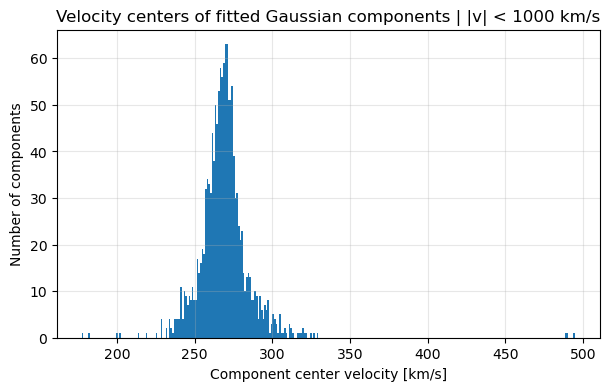

In [22]:
import matplotlib.pyplot as plt

vel = df_components["mean_kms"]

vel_filtered = vel[np.abs(vel) < 1000]

plt.figure(figsize=(7, 4))
plt.hist(vel_filtered, bins=300)
plt.xlabel("Component center velocity [km/s]")
plt.ylabel("Number of components")
plt.title("Velocity centers of fitted Gaussian components | |v| < 1000 km/s")
plt.grid(alpha=0.3)
plt.show()

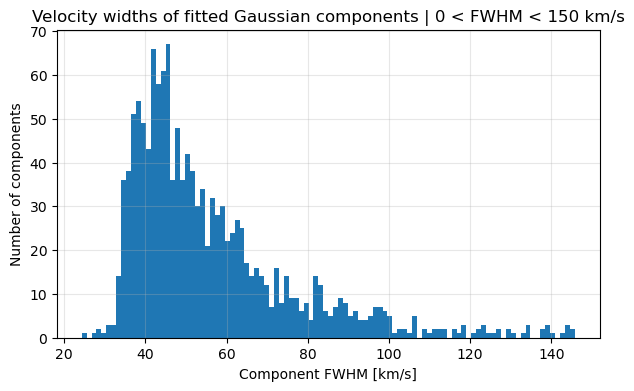

In [23]:
fwhm = df_components["fwhm_kms"]

fwhm_filtered = fwhm[(fwhm > 0) & (fwhm < 150)]

plt.figure(figsize=(7, 4))
plt.hist(fwhm_filtered, bins=100)
plt.xlabel("Component FWHM [km/s]")
plt.ylabel("Number of components")
plt.title("Velocity widths of fitted Gaussian components | 0 < FWHM < 150 km/s")
plt.grid(alpha=0.3)
plt.show()

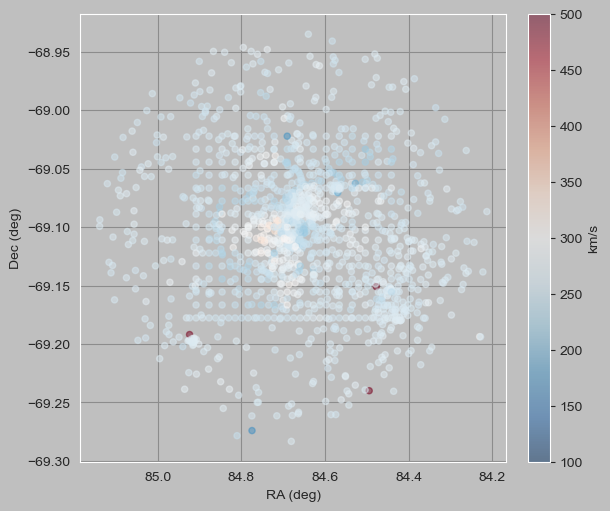

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig, ax = plt.subplots(figsize=(6,5), constrained_layout=True)
    rad_vel = ax.scatter(df_components['ra_deg'], df_components['dec_deg'],
                             s=20.0, 
                             c=df_components['mean_kms'],#-df_components['V_mean'], 
                             cmap='RdBu_r',
                             vmin=100,
                             vmax=500,
                         alpha = 0.5
                        )
    ax.invert_xaxis()
    ax.set_xlabel("RA (deg)")
    ax.set_ylabel("Dec (deg)")
    #ax.set_title(r'H$\alpha$ - H$\beta$')
    fig.colorbar(rad_vel, ax=ax, label='km/s')
    plt.show()

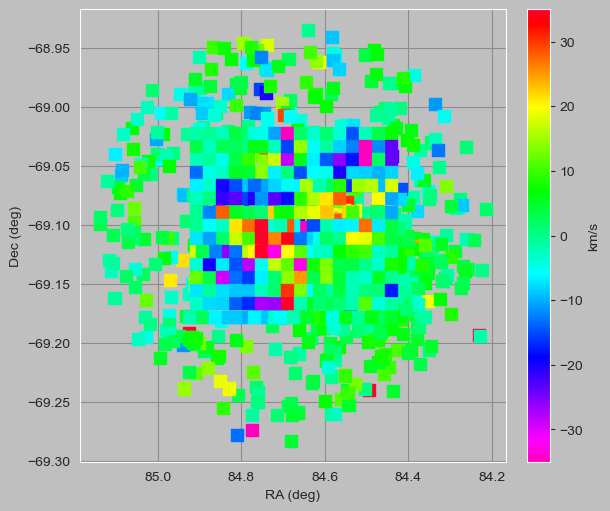

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)

jitter_ra = 0.000   # degrees
jitter_dec = 0.000  # degrees

ra_jittered = df_components["ra_deg"] + rng.normal(0, jitter_ra, size=len(df_components))
dec_jittered = df_components["dec_deg"] + rng.normal(0, jitter_dec, size=len(df_components))

cvals = df_components["mean_kms"] - 267.4

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig, ax = plt.subplots(figsize=(6,5), constrained_layout=True)

    rad_vel = ax.scatter(
        ra_jittered,
        dec_jittered,
        s=75.0,
        c=cvals,
   #     cmap="RdBu_r",
        cmap="gist_rainbow_r",
        vmin=-35,
        vmax=+35,
        marker = 's'
    )

    ax.invert_xaxis()
    ax.set_xlabel("RA (deg)")
    ax.set_ylabel("Dec (deg)")

    fig.colorbar(rad_vel, ax=ax, label="km/s")
    plt.show()

In [26]:
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord

# Center the artificial WCS on 30 Dor / Tarantula
c0 = SkyCoord.from_name("Tarantula")

wcs = WCS(naxis=2)
wcs.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs.wcs.cunit = ["deg", "deg"]

# Reference sky coordinate
wcs.wcs.crval = [c0.ra.deg, c0.dec.deg]

# Reference pixel
wcs.wcs.crpix = [500, 500]

# Pixel scale in degrees/pixel
# Negative RA scale gives standard astronomical orientation
wcs.wcs.cdelt = [-0.00005, 0.00005]

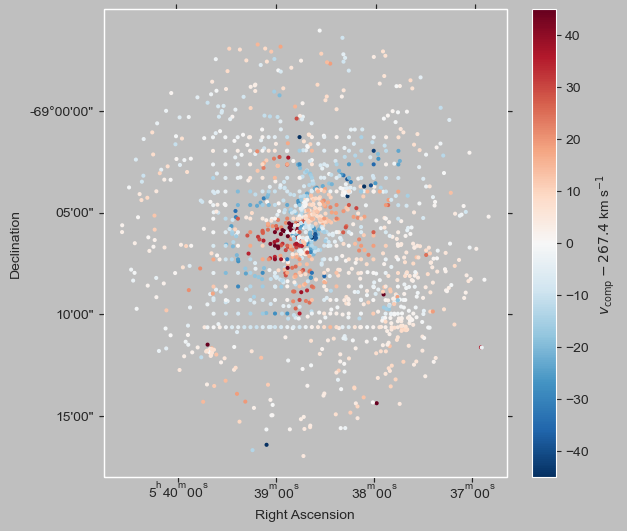

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from astropy.visualization.wcsaxes import WCSAxes

rng = np.random.default_rng(42)

jitter_ra = 0.000
jitter_dec = 0.000

ra_jittered = df_components["ra_deg"].to_numpy() + rng.normal(
    0, jitter_ra, size=len(df_components)
)

dec_jittered = df_components["dec_deg"].to_numpy() + rng.normal(
    0, jitter_dec, size=len(df_components)
)

cvals = df_components["mean_kms"].to_numpy() - 267.4

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig = plt.figure(figsize=(7, 6))

    # Explicit WCSAxes construction
    ax = WCSAxes(
        fig,
        [0.12, 0.12, 0.72, 0.78],   # [left, bottom, width, height]
        wcs=wcs,
    )

    fig.add_axes(ax)

    rad_vel = ax.scatter(
        ra_jittered,
        dec_jittered,
        s=15.0,
        c=cvals,
        cmap="RdBu_r",
        vmin=-45,
        vmax=+45,
        marker=".",
        transform=ax.get_transform("world"),
    )

    ax.coords[0].set_axislabel("Right Ascension")
    ax.coords[1].set_axislabel("Declination")

    ax.coords[0].set_major_formatter("hh:mm:ss")
    ax.coords[1].set_major_formatter("dd:mm:ss")

    ax.grid(color="0.55", alpha=0.6, linestyle="--")

    fig.colorbar(
        rad_vel,
        ax=ax,
        label=r"$v_{\rm comp} - 267.4$ km s$^{-1}$",
    )

    plt.show()

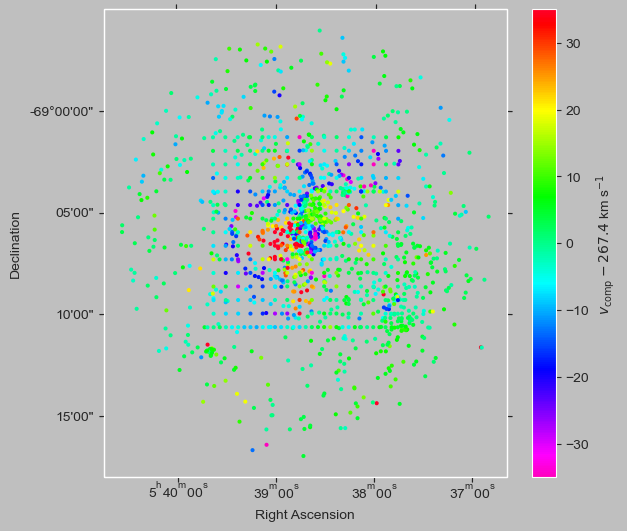

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from astropy.visualization.wcsaxes import WCSAxes

rng = np.random.default_rng(42)

jitter_ra = 0.000
jitter_dec = 0.000

ra_jittered = df_components["ra_deg"].to_numpy() + rng.normal(
    0, jitter_ra, size=len(df_components)
)

dec_jittered = df_components["dec_deg"].to_numpy() + rng.normal(
    0, jitter_dec, size=len(df_components)
)

cvals = df_components["mean_kms"].to_numpy() - 267.4

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig = plt.figure(figsize=(7, 6))

    # Explicit WCSAxes construction
    ax = WCSAxes(
        fig,
        [0.12, 0.12, 0.72, 0.78],   # [left, bottom, width, height]
        wcs=wcs,
    )

    fig.add_axes(ax)

    rad_vel = ax.scatter(
        ra_jittered,
        dec_jittered,
        s=15.0,
        c=cvals,
        cmap="gist_rainbow_r",
        vmin=-35,
        vmax=+35,
        marker=".",
        transform=ax.get_transform("world"),
    )

    ax.coords[0].set_axislabel("Right Ascension")
    ax.coords[1].set_axislabel("Declination")

    ax.coords[0].set_major_formatter("hh:mm:ss")
    ax.coords[1].set_major_formatter("dd:mm:ss")

    ax.grid(color="0.55", alpha=0.6, linestyle="--")

    fig.colorbar(
        rad_vel,
        ax=ax,
        label=r"$v_{\rm comp} - 267.4$ km s$^{-1}$",
    )

    plt.show()

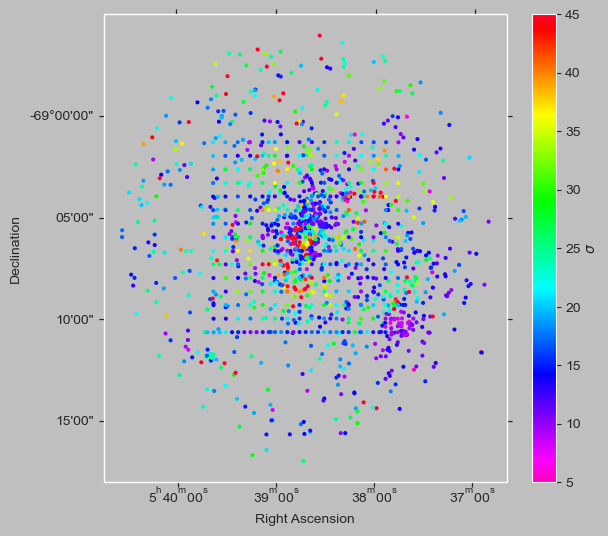

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from astropy.visualization.wcsaxes import WCSAxes

rng = np.random.default_rng(42)

jitter_ra = 0.000
jitter_dec = 0.000

ra_jittered = df_components["ra_deg"].to_numpy() + rng.normal(
    0, jitter_ra, size=len(df_components)
)

dec_jittered = df_components["dec_deg"].to_numpy() + rng.normal(
    0, jitter_dec, size=len(df_components)
)

cvals = df_components["sigma_kms"].to_numpy()

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig = plt.figure(figsize=(7, 6))

    # Explicit WCSAxes construction
    ax = WCSAxes(
        fig,
        [0.12, 0.12, 0.72, 0.78],   # [left, bottom, width, height]
        wcs=wcs,
    )

    fig.add_axes(ax)

    rad_vel = ax.scatter(
        ra_jittered,
        dec_jittered,
        s=15.0,
        c=cvals,
        cmap="gist_rainbow_r",
        vmin=5,
        vmax= 45,
        marker=".",
        transform=ax.get_transform("world"),
    )

    ax.coords[0].set_axislabel("Right Ascension")
    ax.coords[1].set_axislabel("Declination")

    ax.coords[0].set_major_formatter("hh:mm:ss")
    ax.coords[1].set_major_formatter("dd:mm:ss")

    ax.grid(color="0.55", alpha=0.6, linestyle="--")

    fig.colorbar(
        rad_vel,
        ax=ax,
        label=r"$\sigma$",
    )

    plt.show()

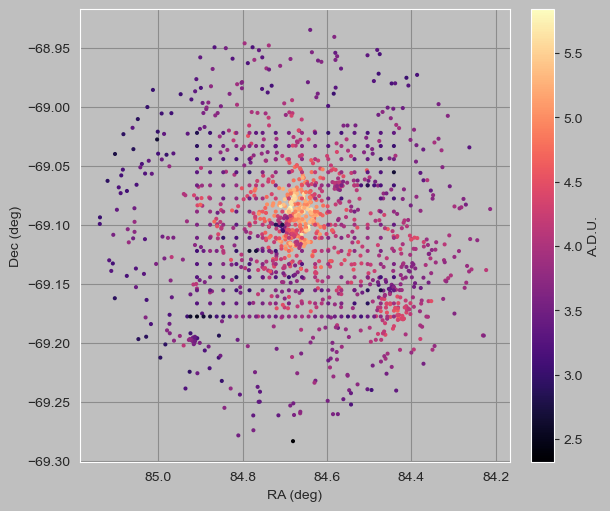

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig, ax = plt.subplots(figsize=(6,5), constrained_layout=True)
    rad_vel = ax.scatter(df_components['ra_deg'], df_components['dec_deg'],
                             s=15.0, 
                             c=np.log10(df_components['amp']),#-df_components['V_mean'], 
                             cmap='magma',
                           #  vmin=100,
                           #  vmax=500,
                         alpha = 1.0,
                         marker = '.'
                        )
    ax.invert_xaxis()
    ax.set_xlabel("RA (deg)")
    ax.set_ylabel("Dec (deg)")
    #ax.set_title(r'H$\alpha$ - H$\beta$')
    fig.colorbar(rad_vel, ax=ax, label='A.D.U.')
    plt.show()

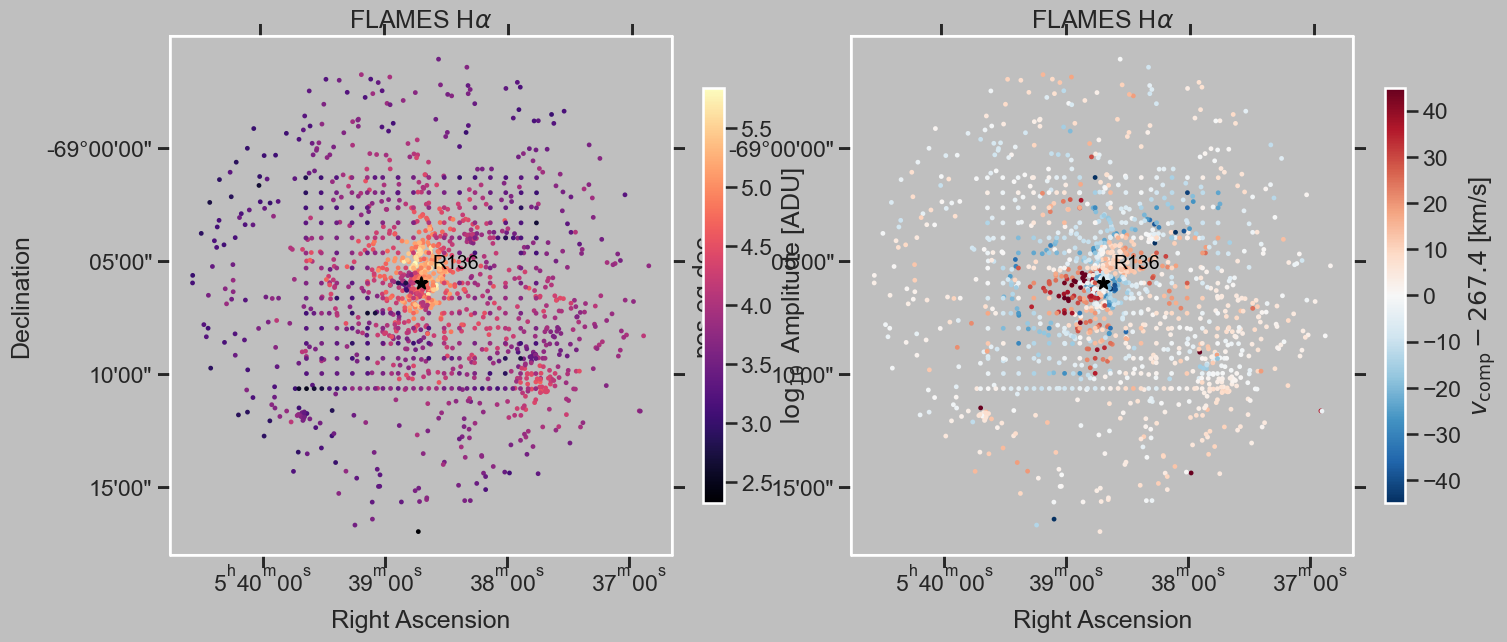

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context("talk")

# -------------------------------------------------------
# Input parameters
# -------------------------------------------------------
v_ref = 267.4  # Reference radial velocity [km/s]

marker_size = 15.0

# Coordinates
ra = df_components["ra_deg"].to_numpy(dtype=float)
dec = df_components["dec_deg"].to_numpy(dtype=float)

# Measurements
amp = df_components["amp"].to_numpy(dtype=float)
vel = df_components["mean_kms"].to_numpy(dtype=float)

# Valid data masks
mask_flux = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(amp)
    & (amp > 0)
)

mask_vel = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(vel)
)

# -------------------------------------------------------
# Figure
# -------------------------------------------------------
with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):

    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(14, 6),
        subplot_kw={"projection": wcs}
    )

    # -------------------------------------------------------
    # Left panel: Logarithm of amplitude
    # -------------------------------------------------------
    im1 = ax1.scatter(
        ra[mask_flux],
        dec[mask_flux],
        s=marker_size,
        c=np.log10(amp[mask_flux]),
        cmap="magma",
        marker=".",
        alpha=1.0,
        transform=ax1.get_transform("world")
    )

    cbar1 = fig.colorbar(
        im1,
        ax=ax1,
        label=r"$\log_{10}$ Amplitude [ADU]",
        shrink=0.8
    )

    ax1.set_xlabel("Right Ascension")
    ax1.set_ylabel("Declination")
    ax1.set_title(r"FLAMES H$\alpha$")

    ax1.coords[0].set_major_formatter("hh:mm:ss")
    ax1.coords[1].set_major_formatter("dd:mm:ss")

    ax1.grid(
        color="white",
        alpha=0.4,
        linestyle="--"
    )

    # R136 position
    ax1.scatter(
        c0.ra.deg,
        c0.dec.deg,
        transform=ax1.get_transform("world"),
        color="black",
        s=80,
        marker="*",
        zorder=5
    )

    ax1.annotate(
        "R136",
        xy=(c0.ra.deg, c0.dec.deg),
        xycoords=ax1.get_transform("world"),
        xytext=(8, 8),
        textcoords="offset points",
        color="black",
        fontsize=14,
        ha="left",
        va="bottom"
    )

    # -------------------------------------------------------
    # Right panel: Radial velocity
    # -------------------------------------------------------
    im2 = ax2.scatter(
        ra[mask_vel],
        dec[mask_vel],
        s=marker_size,
        c=vel[mask_vel] - v_ref,
        cmap="RdBu_r",
        vmin=-45,
        vmax=45,
        marker=".",
        alpha=1.0,
        transform=ax2.get_transform("world")
    )

    cbar2 = fig.colorbar(
        im2,
        ax=ax2,
        label=r"$v_{\rm comp} - 267.4$ [km/s]",
        shrink=0.8
    )

    ax2.set_xlabel("Right Ascension")
    ax2.set_ylabel("")
    ax2.set_title(r"FLAMES H$\alpha$")

    ax2.coords[0].set_major_formatter("hh:mm:ss")
    ax2.coords[1].set_major_formatter("dd:mm:ss")

    ax2.grid(
        color="white",
        alpha=0.4,
        linestyle="--"
    )

    # R136 position
    ax2.scatter(
        c0.ra.deg,
        c0.dec.deg,
        transform=ax2.get_transform("world"),
        color="black",
        s=80,
        marker="*",
        zorder=5
    )

    ax2.annotate(
        "R136",
        xy=(c0.ra.deg, c0.dec.deg),
        xycoords=ax2.get_transform("world"),
        xytext=(8, 8),
        textcoords="offset points",
        color="black",
        fontsize=14,
        ha="left",
        va="bottom"
    )

    # -------------------------------------------------------
    # Set spatial limits from FLAMES coordinates
    # -------------------------------------------------------
    mask_pos = np.isfinite(ra) & np.isfinite(dec)

    xpix, ypix = wcs.world_to_pixel_values(
        ra[mask_pos],
        dec[mask_pos]
    )

    valid_pix = np.isfinite(xpix) & np.isfinite(ypix)
    xpix = xpix[valid_pix]
    ypix = ypix[valid_pix]

    dx = np.ptp(xpix)
    dy = np.ptp(ypix)

    padding_x = 0.05 * dx
    padding_y = 0.05 * dy

    for ax in (ax1, ax2):
        ax.set_xlim(
            xpix.min() - padding_x,
            xpix.max() + padding_x
        )

        ax.set_ylim(
            ypix.min() - padding_y,
            ypix.max() + padding_y
        )

    # -------------------------------------------------------
    # Layout
    # -------------------------------------------------------
    plt.tight_layout()

    plt.savefig(
        "FLAMES-Dor-H.pdf",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

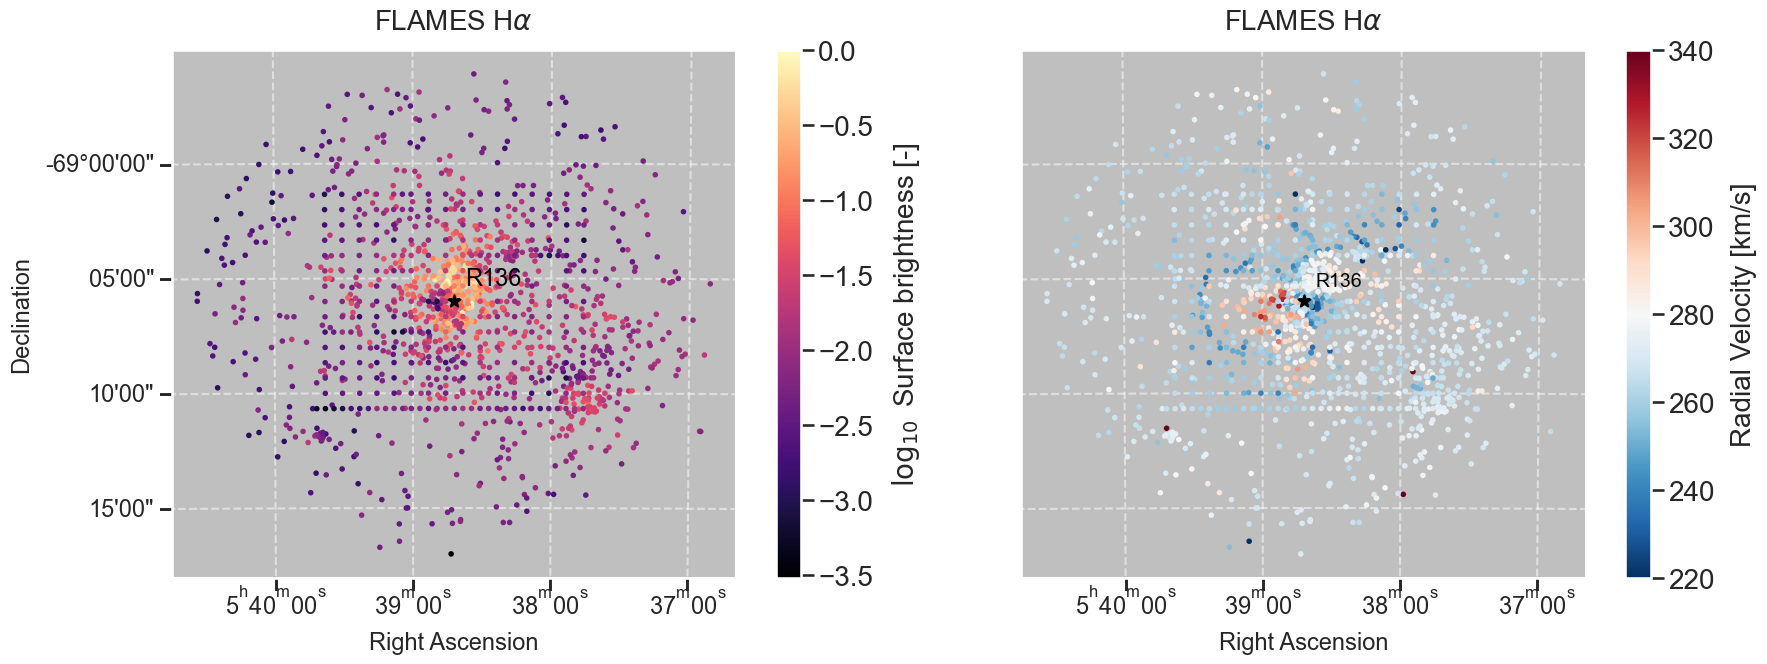

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context("talk")

# ============================================================
# 1. USER INPUTS
# ============================================================

#v_ref = 267.4                 # Reference radial velocity [km/s]
v_ref = 0
marker_size = 25.0            # Scatter marker size
spatial_padding = 0.05        # Fractional spatial padding

# Color scales
flux_cmap = "magma"
velocity_cmap = "RdBu_r"

vmin_velocity = +220
vmax_velocity = +340

# ============================================================
# 2. PREPARE DATA
# ============================================================

# Coordinates
ra = df_components["ra_deg"].to_numpy(dtype=float)
dec = df_components["dec_deg"].to_numpy(dtype=float)

# Measurements
amp = df_components["amp"].to_numpy(dtype=float)
vel = df_components["mean_kms"].to_numpy(dtype=float)

# Valid data masks
mask_flux = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(amp)
    & (amp > 0)
)

mask_vel = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(vel)
)

mask_pos = np.isfinite(ra) & np.isfinite(dec)

# ============================================================
# 3. FIGURE AND GRID SPECIFICATION
# ============================================================

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",     # Gray inside plots
        "figure.facecolor": "white",  # White outside plots
        "grid.color": "0.55",
    }
):

    fig = plt.figure(figsize=(17, 8),facecolor ='white')

    # Five columns:
    # [Flux map | Colorbar | Spacer | Velocity map | Colorbar]

    gs = fig.add_gridspec(
        1, 5,
        width_ratios=[1, 0.045, 0.25, 1, 0.045],
        left=0.07,
        right=0.94,
        bottom=0.16,
        top=0.82,
        wspace=0.15
    )

    # Main WCS axes
    ax1 = fig.add_subplot(
        gs[0, 0],
        projection=wcs
    )

    ax2 = fig.add_subplot(
        gs[0, 3],
        projection=wcs,
        sharey=ax1
    )

    # Independent colorbar axes
    cax1 = fig.add_subplot(gs[0, 1])
    cax2 = fig.add_subplot(gs[0, 4])

    # ========================================================
    # 4. LEFT PANEL: LOGARITHM OF AMPLITUDE
    # ========================================================

    im1 = ax1.scatter(
        ra[mask_flux],
        dec[mask_flux],
        s=marker_size,
        c=np.log10(amp[mask_flux]/np.max(amp[mask_flux])),
        cmap=flux_cmap,
        marker=".",
        alpha=1.0,
        transform=ax1.get_transform("world")
    )

    cbar1 = fig.colorbar(
        im1,
        cax=cax1
    )

    cbar1.set_label(
        r"$\log_{10}$ Surface brightness [-]",
        fontsize=20,
        labelpad=12
    )

    ax1.set_title(
        r"FLAMES H$\alpha$",
        fontsize=20,
        pad=15
    )

    ax1.grid(
        color="white",
        alpha=0.4,
        linestyle="--"
    )

    # R136 position
    ax1.scatter(
        c0.ra.deg,
        c0.dec.deg,
        transform=ax1.get_transform("world"),
        color="black",
        s=80,
        marker="*",
        zorder=5
    )

    ax1.annotate(
        "R136",
        xy=(c0.ra.deg, c0.dec.deg),
        xycoords=ax1.get_transform("world"),
        xytext=(8, 8),
        textcoords="offset points",
        color="black",
        fontsize=17,
        ha="left",
        va="bottom"
    )

    # ========================================================
    # 5. RIGHT PANEL: RADIAL VELOCITY
    # ========================================================

    im2 = ax2.scatter(
        ra[mask_vel],
        dec[mask_vel],
        s=marker_size,
        c=vel[mask_vel] - v_ref,
        cmap=velocity_cmap,
        vmin=vmin_velocity,
        vmax=vmax_velocity,
        marker=".",
        alpha=1.0,
        transform=ax2.get_transform("world")
    )

    cbar2 = fig.colorbar(
        im2,
        cax=cax2
    )

    cbar2.set_label(
        #rf"$v_{{\rm comp}} - {v_ref:g}$ [km/s]",
        'Radial Velocity [km/s]',
        fontsize=20,
        labelpad=12
    )

    ax2.set_title(
        r"FLAMES H$\alpha$",
        fontsize=20,
        pad=15
    )

    ax2.grid(
        color="white",
        alpha=0.4,
        linestyle="--"
    )

    # R136 position
    ax2.scatter(
        c0.ra.deg,
        c0.dec.deg,
        transform=ax2.get_transform("world"),
        color="black",
        s=80,
        marker="*",
        zorder=5
    )

    ax2.annotate(
        "R136",
        xy=(c0.ra.deg, c0.dec.deg),
        xycoords=ax2.get_transform("world"),
        xytext=(8, 8),
        textcoords="offset points",
        color="black",
        fontsize=14,
        ha="left",
        va="bottom"
    )

    # ========================================================
    # 6. SPATIAL LIMITS
    # ========================================================

    # Convert world coordinates to WCS pixel coordinates
    xpix, ypix = wcs.world_to_pixel_values(
        ra[mask_pos],
        dec[mask_pos]
    )

    valid_pix = np.isfinite(xpix) & np.isfinite(ypix)

    xpix = xpix[valid_pix]
    ypix = ypix[valid_pix]

    # Spatial extent
    dx = np.ptp(xpix)
    dy = np.ptp(ypix)

    padding_x = spatial_padding * dx
    padding_y = spatial_padding * dy

    xmin = xpix.min() - padding_x
    xmax = xpix.max() + padding_x

    ymin = ypix.min() - padding_y
    ymax = ypix.max() + padding_y

    # Identical X-axis limits
    ax1.set_xlim(xmin, xmax)
    ax2.set_xlim(xmin, xmax)

    # Shared Y-axis limits
    ax1.set_ylim(ymin, ymax)

    # ========================================================
    # 7. WCS AXIS FORMATTING
    # ========================================================

    for ax in (ax1, ax2):

        # Sexagesimal coordinates
        ax.coords[0].set_major_formatter("hh:mm:ss")
        ax.coords[1].set_major_formatter("dd:mm:ss")

        # RA coordinates at bottom
        ax.coords[0].set_ticks_position("b")
        ax.coords[0].set_ticklabel_position("b")
        ax.coords[0].set_axislabel_position("b")

        # Dec coordinates on left
        ax.coords[1].set_ticks_position("l")
        ax.coords[1].set_ticklabel_position("l")
        ax.coords[1].set_axislabel_position("l")

        # Tick formatting
        ax.coords[0].set_ticklabel(
            size=17,
            exclude_overlapping=True
        )

        ax.coords[1].set_ticklabel(
            size=17,
            exclude_overlapping=True
        )

        # Right Ascension label
        ax.coords[0].set_axislabel(
            "Right Ascension",
            size=17
        )

    # --------------------------------------------------------
    # Left panel: show Declination labels
    # --------------------------------------------------------

    ax1.coords[1].set_axislabel(
        "Declination",
        size=17
    )

    ax1.coords[1].set_ticklabel_visible(True)
    ax1.coords[1].set_ticks_visible(True)

    # --------------------------------------------------------
    # Right panel: hide Declination labels and ticks
    # --------------------------------------------------------

    ax2.coords[1].set_axislabel("")

    ax2.coords[1].set_ticklabel_visible(False)
    ax2.coords[1].set_ticks_visible(False)

    # ========================================================
    # 8. COLORBAR FORMATTING
    # ========================================================

    for cbar in (cbar1, cbar2):

        cbar.ax.tick_params(
            labelsize=20
        )

    # ========================================================
    # 9. SAVE AND DISPLAY
    # ========================================================

    # Do not use tight_layout() with manually arranged GridSpec

    ax1.grid(color="white", alpha=0.5, linestyle="--")
    ax2.grid(color="white", alpha=0.5, linestyle="--")
    
    plt.savefig(
        "FLAMES-Dor-H.pdf",
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

In [33]:
FILENAME_COMPONENTS_CSV = out_dir / "df_components.csv"

df_components.to_csv(FILENAME_COMPONENTS_CSV, index=False)

print("Saved:")
print(FILENAME_SUMMARY_CSV)

Saved:
/Users/javier/FLAMES_30dor/gausspyp_v02.1/gausspy_validation/df_validation_summary.csv


In [45]:
arr0 = df_components["ra_deg"]
arr1 = df_components["dec_deg"]
#arr2 = df_components["mean_kms"].to_numpy() - 267.4
arr2 = df_components["mean_kms"].to_numpy()
arr3 = np.log10(df_components['amp'])
arr4 = np.array([x[0] for x in df_components["sigma_kms"]])

In [46]:
arr4

array([10.7056323 , 11.37604328, 10.31462402, ..., 24.74750163,
       16.7103895 , 26.66623955])

In [47]:
temp_array = np.column_stack((arr0, arr1, arr2, arr3, arr4))

In [48]:
temp_array[0]

array([ 84.550875  , -69.14891667,  -2.77557602,   3.98013049,
        10.7056323 ])

In [49]:
import json

class MyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        elif isinstance(obj, np.floating):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        else:
            return super(MyEncoder, self).default(obj)


name = "FLAMES-30Dor-6563"
data_export_list = {
        "name": name,
        "data": temp_array,
    }

jsonfilename =  name + "-l.json"
with open(jsonfilename, "w") as f:
     json.dump(data_export_list, fp=f, indent=3, cls=MyEncoder)

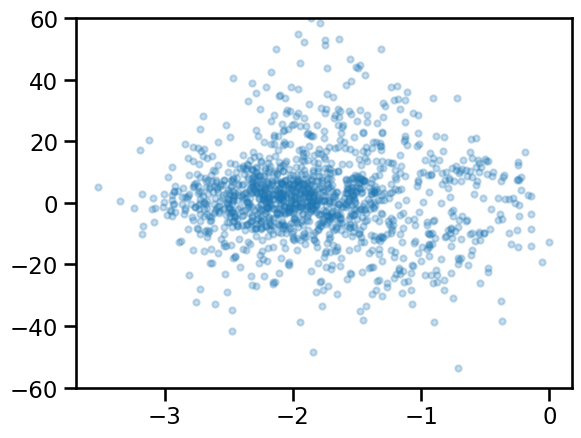

In [39]:
x = np.log10(df_components['amp']/max(df_components['amp']))
y =  df_components["mean_kms"]-267
plt.scatter(x,y, marker = '.', alpha=0.25)
plt.ylim(-60, 60)
plt.show()